Total loaded rows: 2749
Rows after cleaning: 2746


/tmp/ipykernel_1785/2608521373.py:78: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(data=data, x="label", palette=["indianred", "seagreen"])


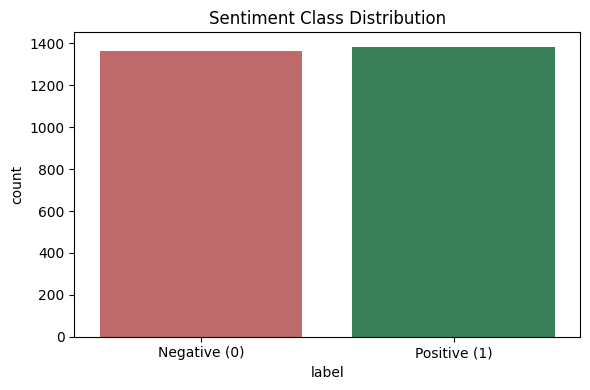

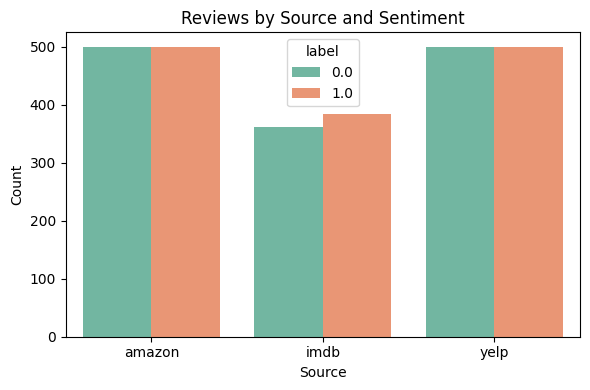

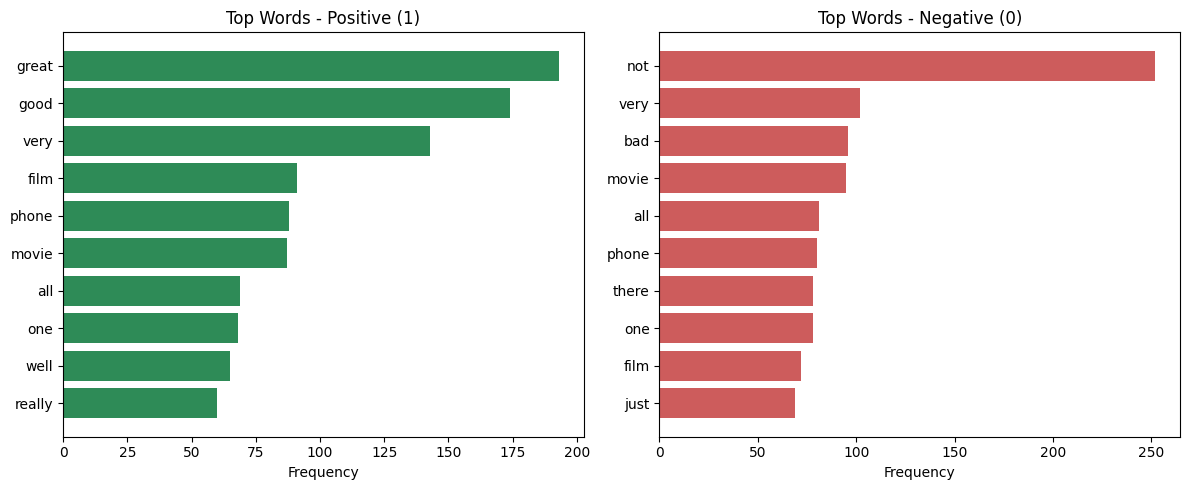

Vocabulary size: 4329

=== Logistic Regression ===
Accuracy : 0.8182
Precision: 0.8391
Recall   : 0.7906
F1 Score : 0.8141

=== Linear SVM ===
Accuracy : 0.82
Precision: 0.8225
Recall   : 0.8195
F1 Score : 0.821


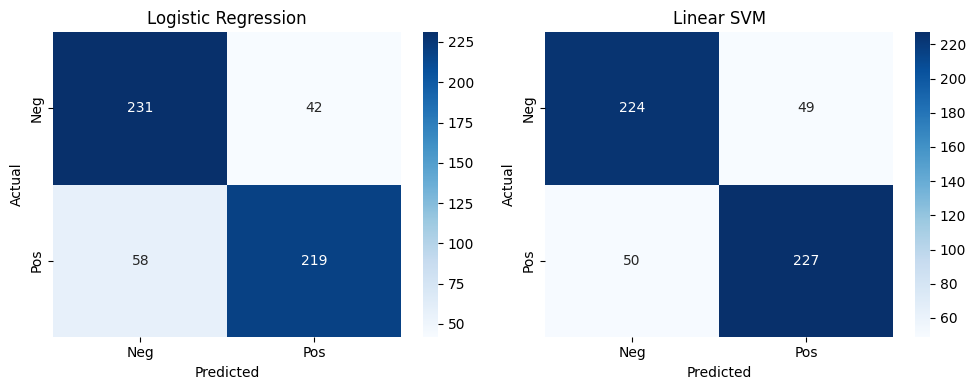

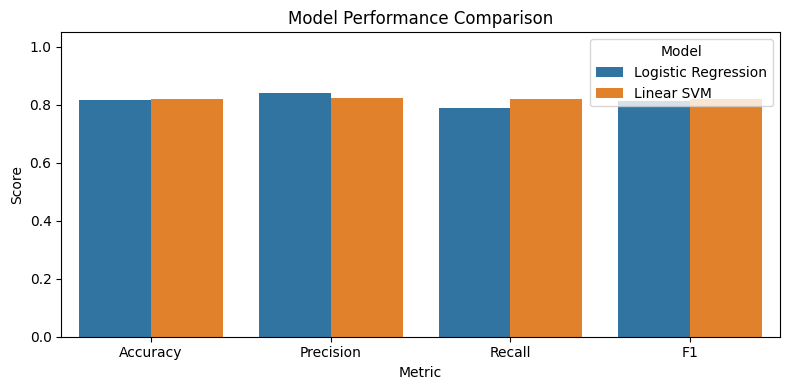


=== New Sentence Predictions ===
I really loved this movie, it was great!  -->  LR: Pos | SVM: Pos
The food was cold and service was bad.  -->  LR: Neg | SVM: Neg
This phone has an amazing camera.  -->  LR: Pos | SVM: Pos
I would not recommend this to anyone.  -->  LR: Neg | SVM: Neg
It was okay, nothing special.  -->  LR: Neg | SVM: Neg
The room wasn't clean at all.  -->  LR: Neg | SVM: Neg
The movie was not bad at all.  -->  LR: Neg | SVM: Neg
Oh great, another broken phone.  -->  LR: Pos | SVM: Pos


In [1]:
import os
import re
import urllib.request
import zipfile
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from sklearn.feature_extraction.text import CountVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
)
from sklearn.model_selection import train_test_split
from sklearn.svm import LinearSVC

# 1. Dataset zip download and extract
zip_url = "https://archive.ics.uci.edu/static/public/331/sentiment+labelled+sentences.zip"
zip_path = "sentiment_data.zip"
extract_dir = "sentiment_extracted"

urllib.request.urlretrieve(zip_url, zip_path)

with zipfile.ZipFile(zip_path, "r") as zf:
  zf.extractall(extract_dir)

file_list = []
for root, _, files in os.walk(extract_dir):
  for f in files:
    if f.endswith(".txt") and (
        "amazon" in f.lower() or "imdb" in f.lower() or "yelp" in f.lower()
    ):
      src_name = (
          "amazon"
          if "amazon" in f.lower()
          else ("imdb" if "imdb" in f.lower() else "yelp")
      )
      file_list.append((os.path.join(root, f), src_name))

part_dfs = []
for fpath, source in file_list:
  temp = pd.read_csv(
      fpath, sep="\t", header=None, names=["text", "label"], encoding="utf-8"
  )
  temp["source"] = source
  part_dfs.append(temp)

data = pd.concat(part_dfs, ignore_index=True)
print("Total loaded rows:", len(data))

# 2. Text preprocessing
re_non_alpha = re.compile(r"[^a-z\s]")
re_multi_space = re.compile(r"\s+")


def clean_text(raw):
  if pd.isna(raw):
    return ""
  txt = str(raw).lower()
  txt = re_non_alpha.sub(" ", txt)
  txt = re_multi_space.sub(" ", txt).strip()
  return txt


data["clean_text"] = data["text"].apply(clean_text)
valid_rows = data["clean_text"].str.len() > 0
data = data[valid_rows].reset_index(drop=True)
print("Rows after cleaning:", len(data))

# 3. EDA Graphs
# Graph A: Class distribution
plt.figure(figsize=(6, 4))
ax = sns.countplot(data=data, x="label", palette=["indianred", "seagreen"])
ax.set_xticks([0, 1])
ax.set_xticklabels(["Negative (0)", "Positive (1)"])
ax.set_title("Sentiment Class Distribution")
plt.tight_layout()
plt.savefig("class_distribution.png", dpi=150)
plt.show()

# Graph B: Source distribution (Amazon, IMDB, Yelp)
plt.figure(figsize=(6, 4))
ax_src = sns.countplot(data=data, x="source", hue="label", palette="Set2")
ax_src.set_title("Reviews by Source and Sentiment")
ax_src.set_xlabel("Source")
ax_src.set_ylabel("Count")
plt.tight_layout()
plt.savefig("source_distribution.png", dpi=150)
plt.show()

# Graph C: Top words per class
stop_words = {
    "the",
    "a",
    "an",
    "and",
    "or",
    "but",
    "if",
    "in",
    "on",
    "at",
    "to",
    "for",
    "of",
    "with",
    "is",
    "was",
    "were",
    "be",
    "been",
    "it",
    "this",
    "that",
    "i",
    "you",
    "he",
    "she",
    "they",
    "we",
    "my",
    "your",
    "as",
    "so",
    "have",
    "has",
    "had",
    "are",
    "for",
    "on",
    "with",
}


def get_top_words(df_sub, n=10):
  counts = {}
  for line in df_sub["clean_text"]:
    for w in line.split():
      if w not in stop_words and len(w) > 1:
        counts[w] = counts.get(w, 0) + 1
  return sorted(counts.items(), key=lambda x: x[1], reverse=True)[:n]


pos_words = get_top_words(data[data["label"] == 1], n=10)
neg_words = get_top_words(data[data["label"] == 0], n=10)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))
ax1.barh(
    [w for w, _ in pos_words][::-1],
    [c for _, c in pos_words][::-1],
    color="seagreen",
)
ax1.set_title("Top Words - Positive (1)")
ax1.set_xlabel("Frequency")

ax2.barh(
    [w for w, _ in neg_words][::-1],
    [c for _, c in neg_words][::-1],
    color="indianred",
)
ax2.set_title("Top Words - Negative (0)")
ax2.set_xlabel("Frequency")

plt.tight_layout()
plt.savefig("top_words_by_class.png", dpi=150)
plt.show()

# 4. Train / Test split (80/20)
X_train, X_test, y_train, y_test = train_test_split(
    data["clean_text"],
    data["label"],
    test_size=0.2,
    random_state=42,
    stratify=data["label"],
)

# 5. Bag-of-Words representation
bow = CountVectorizer()
X_train_vec = bow.fit_transform(X_train)
X_test_vec = bow.transform(X_test)
print("Vocabulary size:", len(bow.vocabulary_))

# 6 & 7. Train & Evaluate Models
clf_lr = LogisticRegression(max_iter=1000, random_state=42)
clf_svm = LinearSVC(random_state=42)

clf_lr.fit(X_train_vec, y_train)
clf_svm.fit(X_train_vec, y_train)

metrics_rows = []
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for idx, (name, model) in enumerate(
    [("Logistic Regression", clf_lr), ("Linear SVM", clf_svm)]
):
  y_pred = model.predict(X_test_vec)
  acc = accuracy_score(y_test, y_pred)
  prec = precision_score(y_test, y_pred)
  rec = recall_score(y_test, y_pred)
  f1 = f1_score(y_test, y_pred)
  metrics_rows.append((name, acc, prec, rec, f1))

  print(f"\n=== {name} ===")
  print("Accuracy :", round(acc, 4))
  print("Precision:", round(prec, 4))
  print("Recall   :", round(rec, 4))
  print("F1 Score :", round(f1, 4))

  cm = confusion_matrix(y_test, y_pred)
  sns.heatmap(
      cm,
      annot=True,
      fmt="d",
      cmap="Blues",
      ax=axes[idx],
      xticklabels=["Neg", "Pos"],
      yticklabels=["Neg", "Pos"],
  )
  axes[idx].set_title(name)
  axes[idx].set_xlabel("Predicted")
  axes[idx].set_ylabel("Actual")

plt.tight_layout()
plt.savefig("confusion_matrices.png", dpi=150)
plt.show()

# Graph D: Model Metrics Comparison
metrics_df = pd.DataFrame(
    metrics_rows, columns=["Model", "Accuracy", "Precision", "Recall", "F1"]
)
metrics_melted = metrics_df.melt(
    id_vars="Model", var_name="Metric", value_name="Score"
)

plt.figure(figsize=(8, 4))
ax_m = sns.barplot(data=metrics_melted, x="Metric", y="Score", hue="Model")
ax_m.set_ylim(0, 1.05)
ax_m.set_title("Model Performance Comparison")
plt.tight_layout()
plt.savefig("model_metrics.png", dpi=150)
plt.show()

# 8. Test new sentences
test_cases = [
    "I really loved this movie, it was great!",
    "The food was cold and service was bad.",
    "This phone has an amazing camera.",
    "I would not recommend this to anyone.",
    "It was okay, nothing special.",
    "The room wasn't clean at all.",
    "The movie was not bad at all.",
    "Oh great, another broken phone.",
]

vec_new = bow.transform([clean_text(s) for s in test_cases])
pred_lr = clf_lr.predict(vec_new)
pred_svm = clf_svm.predict(vec_new)

print("\n=== New Sentence Predictions ===")
for sent, p1, p2 in zip(test_cases, pred_lr, pred_svm):
  print(
      f"{sent}  -->  LR: {'Pos' if p1==1 else 'Neg'} | SVM:"
      f" {'Pos' if p2==1 else 'Neg'}"
  )

In [ ]:
from google.colab import drive
drive.mount('/content/drive')